<a href="https://colab.research.google.com/github/devarshnayyar-a11y/Research-Project-for-CSAI-Research-a-thon/blob/main/Untitled0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

IMPORTING THE MODEL

In [10]:
import gc
import torch
from diffusers import DiffusionPipeline

# Safely remove the previous model, only if it exists
if "pipe" in globals():
    del pipe

gc.collect()
torch.cuda.empty_cache()

# Load RealVisXL
pipe = DiffusionPipeline.from_pretrained(
    "SG161222/RealVisXL_V5.0",
    torch_dtype=torch.float16,
    use_safetensors=True
)

# Save GPU memory on the Colab T4
pipe.enable_model_cpu_offload()

print("Model loaded:", pipe.__class__.__name__)
print("GPU:", torch.cuda.get_device_name(0))

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Model loaded: StableDiffusionXLPipeline
GPU: Tesla T4


In [11]:
print("Kernel is responsive")
print("CUDA available:", torch.cuda.is_available())
print("Pipeline exists:", "pipe" in globals())

Kernel is responsive
CUDA available: True
Pipeline exists: True


TESTING THE MODEL ONCE ON A BASIC PROMPT

  0%|          | 0/30 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


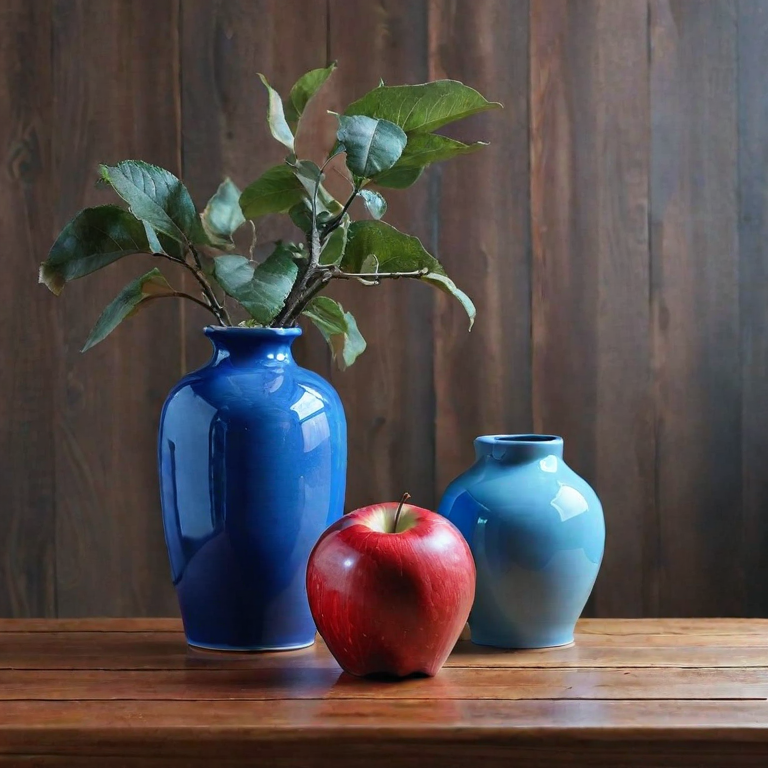

In [16]:
prompt = "A realistic photograph of exactly one red apple beside exactly one blue ceramic vase on a wooden table. Both objects are fully visible. No plants, no additional vases, and no other objects."

generator = torch.Generator(device="cpu").manual_seed(42)

result = pipe(
    prompt=prompt,
    width=768,
    height=768,
    num_inference_steps=30,
    guidance_scale=12,
    generator=generator
)

test_image = result.images[0]
display(test_image)

Yeah above image has duplicate vases so our cross attention reweighting mechanism would help later in it